In [1]:
from pathlib import Path
import config
from extraction import extraire_pdf
from indexing import indexer_document
from utils import calculer_document_id
from vectorstore import get_collection
from indexing import supprimer_document

c:\WorkDir\IAGEN\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [4]:
pdf = config.PDF_DIR / "Attention is all you need.pdf"
doc_id = calculer_document_id(pdf)

In [5]:
print("Before:", get_collection().count())
supprimer_document(doc_id)
print("After: ", get_collection().count()) 

Before: 174
After:  0


In [6]:
res = extraire_pdf(pdf, config.OUTPUT_DIR)
print(res.nombre_pages, "pages |", res.nombre_images, "images")
print(res.avertissements)

11 pages | 3 images
[]


In [7]:
idx = indexer_document(doc_id, config.OUTPUT_DIR, pdf.name)
print(idx.fragments_texte, "fragments |", idx.images, "images")

print("Total en base :", get_collection().count())

171 fragments | 3 images
Total en base : 174


In [2]:
from retrieval import rechercher
from utils import afficher_resultats

In [9]:
# requête texte -> textes
afficher_resultats(rechercher(texte="multi-head attention", type_resultat="texte", k=3))


1. TEXTE | PDF : Attention is all you need.pdf | Page : 2 | Similarité cosinus : 0.780
first is a multi - head self - attention mechanism , and the second is a simple , position - 2

2. TEXTE | PDF : Attention is all you need.pdf | Page : 8 | Similarité cosinus : 0.664
), we vary the number of attention heads and the attention key and value dimensions , keeping the amount of computation constant , as described in section 3 . 2 . 2 . while single - head attention is 0 . 9 bleu worse than the best setting , quality also drops off with too many heads . 5

3. TEXTE | PDF : Attention is all you need.pdf | Page : 2 | Similarité cosinus : 0.633
in section 3 . 2 . self - attention , sometimes called intra - attention is an attention mechanism relating different positions of a single sequence in order to compute a representation of the sequence . self - attention has been used successfully in a variety of tasks including reading comprehension , abstractive summarization ,



1. IMAGE | PDF : Attention is all you need.pdf | Page : 4 | Similarité cosinus : 0.264


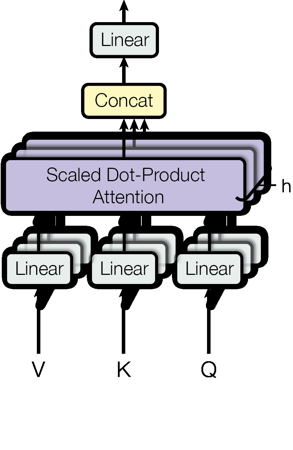


2. IMAGE | PDF : Attention is all you need.pdf | Page : 4 | Similarité cosinus : 0.260


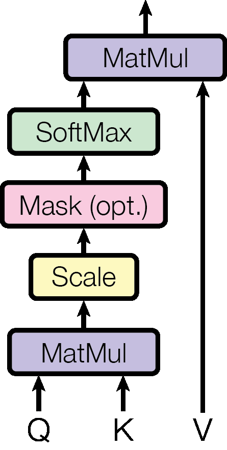


3. IMAGE | PDF : Attention is all you need.pdf | Page : 3 | Similarité cosinus : 0.253


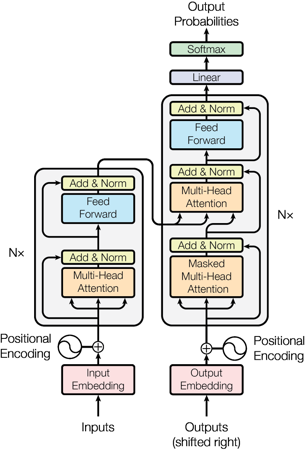

In [10]:
# requête texte -> images
afficher_resultats(rechercher(texte="Transformer model architecture diagram", type_resultat="image", k=3))


1. IMAGE | PDF : Attention is all you need.pdf | Page : 3 | Similarité cosinus : 1.000


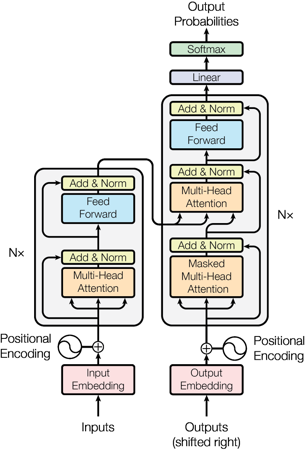


2. IMAGE | PDF : Attention is all you need.pdf | Page : 4 | Similarité cosinus : 0.700


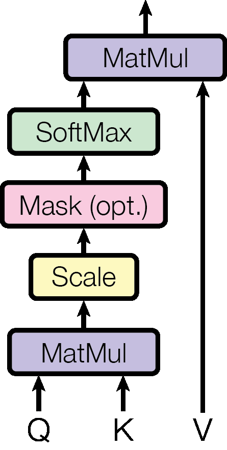


3. IMAGE | PDF : Attention is all you need.pdf | Page : 4 | Similarité cosinus : 0.600


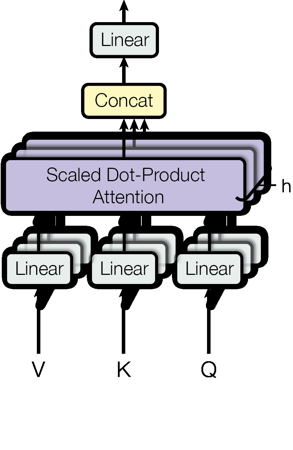


4. TEXTE | PDF : Attention is all you need.pdf | Page : 6 | Similarité cosinus : 0.327
bottoms of the encoder and decoder stacks . the positional encodings have the same dimension dmodel as the embeddings , so that the two can be summed . there are many choices of positional encodings , learned and fixed [ 8 ]. in this work , we use sine and

5. TEXTE | PDF : Attention is all you need.pdf | Page : 3 | Similarité cosinus : 0.317
normalization . we also modify the self - attention sub - layer in the decoder stack to prevent positions from attending to subsequent positions . this masking , combined with fact that the output embeddings are offset by one position , ensures that the predictions for position i can depend only on the known outputs


In [3]:
# requête image -> images et textes
img = next(Path(config.OUTPUT_DIR, "images").iterdir())
afficher_resultats(rechercher(image=img, k=5))

In [12]:
from agent.tool import retriever_tool

print(retriever_tool.invoke({"query": "scaled dot-product attention"}))


[TEXTE] Attention is all you need.pdf p.3 (sim=0.65)
- product attention we call our particular attention " scaled dot - product attention " ( figure 2 ). the input consists of queries and keys of dimension dk , and values of dimension dv . we compute the dot products of the 3

---

[TEXTE] Attention is all you need.pdf p.4 (sim=0.65)
scaled dot - product attention multi - head attention figure 2 : ( left ) scaled dot - product attention . ( right ) multi - head attention consists of several attention layers running in parallel . query with all keys , divide each by √ dk , and apply a softmax function to obtain the weights on

---

[TEXTE] Attention is all you need.pdf p.4 (sim=0.63)
product ( multi - plicative ) attention . dot - product attention is identical to our algorithm , except for the scaling factor of √ dk 1 . additive attention computes the compatibility function using a feed - forward network with a single hidden layer . while the two are similar in theoretical complexity 

In [13]:

print(retriever_tool.invoke({"query": "similar figure", "image_path": str(img)}))

[TEXTE] Attention is all you need.pdf p.6 (sim=0.33)
bottoms of the encoder and decoder stacks . the positional encodings have the same dimension dmodel as the embeddings , so that the two can be summed . there are many choices of positional encodings , learned and fixed [ 8 ]. in this work , we use sine and

---

[TEXTE] Attention is all you need.pdf p.3 (sim=0.32)
normalization . we also modify the self - attention sub - layer in the decoder stack to prevent positions from attending to subsequent positions . this masking , combined with fact that the output embeddings are offset by one position , ensures that the predictions for position i can depend only on the known outputs

---

[TEXTE] Attention is all you need.pdf p.2 (sim=0.31)
model is auto - regressive [ 9 ], consuming the previously generated symbols as additional input when generating the next . the transformer follows this overall architecture using stacked self - attention and point - wise , fully connected layers for bot

In [4]:
from agent.graph import ask

questions = [
    # 1. texte pur : un appel d'outil attendu
    "What is scaled dot-product attention and why is it scaled by sqrt(dk)?",
    # 2. hybride texte + image : deux recherches attendues
    "Show me the Transformer architecture diagram and explain multi-head attention.",
    # 3. requête par image
    f"Find passages and figures related to this image: {img}",
    # 4. question sans rapport : l'agent ne doit pas inventer
    "Who won the 2018 football World Cup?",
    # 5. question à plusieurs sous-questions
    "What BLEU score did the big Transformer get on WMT14 En-De and how long was it trained?",
]


In [5]:
print("\n" + "=" * 80 + "\n" + questions[0] + "\n" + "=" * 80)
ask(questions[0])


What is scaled dot-product attention and why is it scaled by sqrt(dk)?
================================ Human Message =================================

What is scaled dot-product attention and why is it scaled by sqrt(dk)?
================================== Ai Message ==================================
Tool Calls:
  retriever_tool (call-1eb888dc-2cbe-4164-abcb-aab079c090fb)
 Call ID: call-1eb888dc-2cbe-4164-abcb-aab079c090fb
  Args:
    query: scaled dot-product attention definition transformer
================================= Tool Message =================================
Name: retriever_tool

[TEXTE] Attention is all you need.pdf p.3 (sim=0.66)
- product attention we call our particular attention " scaled dot - product attention " ( figure 2 ). the input consists of queries and keys of dimension dk , and values of dimension dv . we compute the dot products of the 3

---

[TEXTE] Attention is all you need.pdf p.4 (sim=0.65)
scaled dot - product attention multi - head attention figu

'Based on the "Attention Is All You Need" paper [pdf p.3–4] and the accompanying diagrams, here is the answer:\n\n## What is scaled dot-product attention?\n\nScaled dot-product attention is the specific attention mechanism introduced in the Transformer architecture. It takes three inputs: **queries (Q)**, **keys (K)**, and **values (V)**, where queries and keys have dimension **dₖ** and values have dimension **dᵥ**.\n\nThe computation proceeds as follows [pdf p.4]:\n1. Compute dot products of the query with all keys: **QKᵀ**\n2. **Scale** each dot product by dividing by **√dₖ**\n3. Apply a **softmax** function to obtain the attention weights\n4. Multiply the weights by the values **V** to get the output\n\nThe formula is shown in Figure 2 (right diagram, Image 2):\n\n**Attention(Q, K, V) = softmax( QKᵀ / √dₖ ) V**\n\n## Why is it scaled by √dₖ?\n\nThe paper explicitly explains the reason [pdf p.4]:\n\n> *"For large values of dₖ, the dot products grow large in magnitude, pushing the sof